 ## Data Coding and Merging

### Import necessary libraries 

In [29]:
#Import Libraries

import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
PBP.describe
PBP.columns.to_list()

Import the “NHL_Team.csv” data file and name the dataframe as “NHL_Team” in Jupyter Notebook.
a) Delete the following variables: “Unnamed:0”, “abbr”, “tname”, “lname”, and “sname”.
b) Rename the variable “name” to “team_name”.

In [30]:
# Import the CSV
NHL_Team = pd.read_csv(r"data/NHL_team.csv")
NHL_Team = NHL_Team.drop(columns=["Unnamed:0","Unnamed: 0","abbr","tname","lname","sname"], errors="ignore")
NHL_Team = NHL_Team.rename(columns={"name":"team_name"})
NHL_Team

,tid,team_name,tricode
0,1,Toronto Maple Leafs,TOR
1,2,Montréal Canadiens,MTL
2,4,Winnipeg Jets,WPG
3,5,Washington Capitals,WSH
4,6,Chicago Blackhawks,CHI
5,7,St. Louis Blues,STL
6,8,Pittsburgh Penguins,PIT
7,10,Edmonton Oilers,EDM
8,11,Calgary Flames,CGY
9,14,Philadelphia Flyers,PHI


Import the “NHL_competition.csv” data file and name the dataframe as “NHL_Competition” in Jupyter Notebook.
a) Delete the following variables: “Unnamed: 0”, “tz”, “start”, and “end”
b) Rename the variable “name” to “competition_name”.

In [31]:
NHL_Competition = pd.read_csv(r"data/NHL_competition.csv")
NHL_Competition = NHL_Competition.drop(columns=["Unnamed:0","Unnamed: 0","tz","start","end"], errors="ignore")
NHL_Competition = NHL_Competition.rename(columns={"name":"competition_name"})
NHL_Competition = NHL_Competition[[c for c in ["comp_id","year","type","competition_name"] if c in NHL_Competition.columns]]

NHL_Competition

,comp_id,year,type,competition_name
0,1,2013,2,2013 NHL Regular Season
1,2,2017,2,2017 NHL Regular Season
2,2453,2013,3,2013 NHL Playoff
3,2541,2017,3,2017 NHL Playoff
4,2661,2012,2,2012 NHL Regular Season
5,2734,2016,2,2016 NHL Regular Season
6,4099,2012,3,2012 NHL Playoff
7,4287,2011,2,2011 NHL Regular Season
8,5181,2016,3,2016 NHL Playoff
9,5385,2015,2,2015 NHL Regular Season


Import the “NHL_game.csv” data file and name the dataframe as “NHL_Game” in Jupyter Notebook.
a) Delete the following variables: “X”, “period”, and “status”.

In [32]:
NHL_game = pd.read_csv(r"data/NHL_game.csv")
NHL_game = NHL_game.drop(columns=["X","period","status"], errors="ignore")
NHL_game

,gid,comp_id,date,ascore,hscore,home_away,tid
0,37,2,10/7/2017,NaN,NaN,away,25
1,67,2,10/9/2017,NaN,NaN,away,29
2,154,1,10/14/2013,NaN,NaN,away,29
3,278,1,10/24/2013,NaN,NaN,away,53
4,291,1,10/25/2013,NaN,NaN,away,5
...,...,...,...,...,...,...,...
18941,4827,4287,11/19/2011,0.0,3.0,home,22
18942,7227,5662,2/4/2011,2.0,3.0,home,14
18943,790,2,12/2/2017,2.0,1.0,home,45
18944,2850,2734,10/21/2016,4.0,2.0,home,11


Merge the dataframe “NHL_Team” into the dataframe “NHL_Game” by “tid.” Continue to name the merged dataframe as “NHL_Game.”

In [33]:
NHL_game = NHL_game.merge(NHL_Team, on='tid', how='left')

# Preview the result
NHL_game.head()

,gid,comp_id,date,ascore,hscore,home_away,tid,team_name,tricode
0,37,2,10/7/2017,NaN,NaN,away,25,Tampa Bay Lightning,TBL
1,67,2,10/9/2017,NaN,NaN,away,29,New Jersey Devils,NJD
2,154,1,10/14/2013,NaN,NaN,away,29,New Jersey Devils,NJD
3,278,1,10/24/2013,NaN,NaN,away,53,Vancouver Canucks,VAN
4,291,1,10/25/2013,NaN,NaN,away,5,Washington Capitals,WSH


Merge the dataframe “NHL_Competition” into the dataframe “NHL_Game” by “comp_id.” Continue to name the merged dataframe as “NHL_Game.”
In the merged “NHL_Game” dataframe, create a variable “hgd” to indicate the goal difference between home and away score (hscore – ascore) and delete observations with missing value in the variable “hgd”.

In [34]:
NHL_game = NHL_game.merge(NHL_Competition, on='comp_id', how='left')

NHL_game['hgd'] = NHL_game['hscore'] - NHL_game['ascore']

NHL_game = NHL_game.dropna()

NHL_game.head()

,gid,comp_id,date,ascore,hscore,home_away,tid,team_name,tricode,year,type,competition_name,hgd
220,6114,5385,12/4/2015,5.0,1.0,away,29,New Jersey Devils,NJD,2015,2,2015 NHL Regular Season,-4.0
221,4790,4287,11/16/2011,1.0,3.0,away,5,Washington Capitals,WSH,2011,2,2011 NHL Regular Season,2.0
222,273,1,10/23/2013,6.0,1.0,away,32,Ottawa Senators,OTT,2013,2,2013 NHL Regular Season,-5.0
223,3936,2661,4/17/2013,3.0,2.0,away,17,Buffalo Sabres,BUF,2012,2,2012 NHL Regular Season,-1.0
224,5761,5385,11/7/2015,2.0,4.0,away,6,Chicago Blackhawks,CHI,2015,2,2015 NHL Regular Season,2.0


Convert the type of the “date” variable from “object” to “datetime.”
Sort the NHL games by “date” and show the first 15 observations.

In [35]:
NHL_game['date'] = pd.to_datetime(NHL_game['date'])

NHL_game.sort_values('date').head(15)

,gid,comp_id,date,ascore,hscore,home_away,tid,team_name,tricode,year,type,competition_name,hgd
2353,5666,5662,2010-10-07,4.0,3.0,away,66,Carolina Hurricanes,CAR,2010,2,2010 NHL Regular Season,-1.0
13052,5664,5662,2010-10-07,3.0,2.0,home,8,Pittsburgh Penguins,PIT,2010,2,2010 NHL Regular Season,-1.0
3579,5664,5662,2010-10-07,3.0,2.0,away,14,Philadelphia Flyers,PHI,2010,2,2010 NHL Regular Season,-1.0
8490,5662,5662,2010-10-07,2.0,3.0,away,2,Montréal Canadiens,MTL,2010,2,2010 NHL Regular Season,1.0
17963,5662,5662,2010-10-07,2.0,3.0,home,1,Toronto Maple Leafs,TOR,2010,2,2010 NHL Regular Season,1.0
11826,5666,5662,2010-10-07,4.0,3.0,home,35,Minnesota Wild,MIN,2010,2,2010 NHL Regular Season,-1.0
18320,5670,5662,2010-10-08,0.0,4.0,home,10,Edmonton Oilers,EDM,2010,2,2010 NHL Regular Season,4.0
8847,5670,5662,2010-10-08,0.0,4.0,away,11,Calgary Flames,CGY,2010,2,2010 NHL Regular Season,4.0
2194,5674,5662,2010-10-08,4.0,3.0,away,46,Dallas Stars,DAL,2010,2,2010 NHL Regular Season,-1.0
16861,5668,5662,2010-10-08,3.0,4.0,home,22,Colorado Avalanche,COL,2010,2,2010 NHL Regular Season,1.0


Drop all observations with missing values, if there is still any, from the “NHL_Game” dataframe.

In [36]:
NHL_game = NHL_game.dropna()


Create two dataframes that separate the “NHL_Game” dataframe by home and away games. Name them “NHL_Home” and “NHL_Away”, respectively.

a) Rename variables:
     i) For away games, rename “ascore” to “goals_for”; rename “hscore” to “goals_against”
     ii) For home games, rename “hscore” to “goals_for”; rename “ascore” to “goals_against” 

b) Create a “win” variable that equals to 1 if the team won the game; 0 if the team lost the game; and 0.5 if it was a draw. 

Append the “NHL_Home” and “NHL_Away” dataframes to be the new “NHL_Game” dataframe.

In [37]:
NHL_Away = NHL_game.loc[NHL_game["home_away"].eq("away")].copy()
NHL_Home = NHL_game.loc[NHL_game["home_away"].eq("home")].copy()

NHL_Away = NHL_Away.rename(columns={'ascore': 'goals_for', 'hscore': 'goals_against'})
NHL_Home = NHL_Home.rename(columns={'hscore': 'goals_for', 'ascore': 'goals_against'})

NHL_Away['win'] = np.select([NHL_Away['goals_for']>NHL_Away['goals_against'], NHL_Away['goals_for']<NHL_Away['goals_against']], [1,0], 0.5)
NHL_Home['win'] = np.select([NHL_Home['goals_for']>NHL_Home['goals_against'], NHL_Home['goals_for']<NHL_Home['goals_against']], [1,0], 0.5)


NHL_game = pd.concat([NHL_Away, NHL_Home], ignore_index=True).sort_values(['date', 'gid', 'tid']).reset_index(drop=True)

NHL_game

,gid,comp_id,date,goals_for,goals_against,home_away,tid,team_name,tricode,year,type,competition_name,hgd,win
0,5662,5662,2010-10-07,3.0,2.0,home,1,Toronto Maple Leafs,TOR,2010,2,2010 NHL Regular Season,1.0,1.0
1,5662,5662,2010-10-07,2.0,3.0,away,2,Montréal Canadiens,MTL,2010,2,2010 NHL Regular Season,1.0,0.0
2,5664,5662,2010-10-07,2.0,3.0,home,8,Pittsburgh Penguins,PIT,2010,2,2010 NHL Regular Season,-1.0,0.0
3,5664,5662,2010-10-07,3.0,2.0,away,14,Philadelphia Flyers,PHI,2010,2,2010 NHL Regular Season,-1.0,1.0
4,5666,5662,2010-10-07,3.0,4.0,home,35,Minnesota Wild,MIN,2010,2,2010 NHL Regular Season,-1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18501,2725,2541,2018-06-03,1.0,3.0,away,59,Vegas Golden Knights,VGK,2017,3,2017 NHL Playoff,2.0,0.0
18502,2727,2541,2018-06-05,6.0,2.0,home,5,Washington Capitals,WSH,2017,3,2017 NHL Playoff,4.0,1.0
18503,2727,2541,2018-06-05,2.0,6.0,away,59,Vegas Golden Knights,VGK,2017,3,2017 NHL Playoff,4.0,0.0
18504,2730,2541,2018-06-08,4.0,3.0,away,5,Washington Capitals,WSH,2017,3,2017 NHL Playoff,-1.0,1.0


Generate a team level dataframe that aggregates the total number of games won, the total number of “goals_for” and “goals_against” for each team in each competition (i.e. grouped by tid, competition_name and type). Name this new dataframe “NHL_Team_Stats”. Make sure to convert the indexes of the new dataframe back as  variables. 

Create a dataframe “NHL_Game_Count” that include the total number of games played by each team in each competition (i.e. grouped by tid, competition_name and type). Name this new variable in the dataframe “game_count”.

In [38]:
NHL_Team_Stats = NHL_game.groupby(["tid","competition_name","type"], as_index=False)[["win","goals_for","goals_against"]].sum()
NHL_Game_Count = NHL_game.groupby(["tid","competition_name","type"]).size().reset_index(name="game_count")
NHL_Team_Stats

,tid,competition_name,type,win,goals_for,goals_against
0,1,2010 NHL Regular Season,2,36.0,223.0,259.0
1,1,2011 NHL Regular Season,2,20.0,129.0,129.0
2,1,2012 NHL Playoff,3,3.0,18.0,22.0
3,1,2012 NHL Regular Season,2,25.0,144.0,129.0
4,1,2013 NHL Regular Season,2,38.0,231.0,250.0
...,...,...,...,...,...,...
364,66,2014 NHL Regular Season,2,30.0,191.0,228.0
365,66,2015 NHL Regular Season,2,34.0,195.0,226.0
366,66,2016 NHL Regular Season,2,35.5,219.0,243.0
367,66,2017 NHL Regular Season,2,35.5,227.0,248.0


Merge dataframes.
a) Merge the “NHL_Game_Count” dataframe into the “NHL_Team_Stats” dataframe by “tid”, “competition_name”, and “type”. Continue to name the merged dataframe “NHL_Team_Stats”.
b) Merge the “NHL_Team” dataframe into the “NHL_Team_Stats” dataframe by “tid”. Continue to name the merged dataframe “NHL_Team_Stats”.

In [39]:
# 1) game count per team per competition
NHL_Game_Count = NHL_game.groupby(["tid","competition_name","type"]).size().reset_index(name="game_count")

# 2a) merge game_count into team stats
NHL_Team_Stats = NHL_Team_Stats.merge(NHL_Game_Count, on=["tid","competition_name","type"], how="left")

# 2b) merge team info into team stats (drop any old team columns first to avoid _x/_y)
NHL_Team_Stats = NHL_Team_Stats.drop(columns=[c for c in NHL_Team_Stats.columns if str(c).startswith(("team_name","tricode"))], errors="ignore")
NHL_Team_Stats = NHL_Team_Stats.merge(NHL_Team[["tid","team_name","tricode"]], on="tid", how="left")

NHL_Team_Stats

,tid,competition_name,type,win,goals_for,goals_against,game_count,team_name,tricode
0,1,2010 NHL Regular Season,2,36.0,223.0,259.0,82,Toronto Maple Leafs,TOR
1,1,2011 NHL Regular Season,2,20.0,129.0,129.0,40,Toronto Maple Leafs,TOR
2,1,2012 NHL Playoff,3,3.0,18.0,22.0,7,Toronto Maple Leafs,TOR
3,1,2012 NHL Regular Season,2,25.0,144.0,129.0,46,Toronto Maple Leafs,TOR
4,1,2013 NHL Regular Season,2,38.0,231.0,250.0,79,Toronto Maple Leafs,TOR
...,...,...,...,...,...,...,...,...,...
364,66,2014 NHL Regular Season,2,30.0,191.0,228.0,82,Carolina Hurricanes,CAR
365,66,2015 NHL Regular Season,2,34.0,195.0,226.0,81,Carolina Hurricanes,CAR
366,66,2016 NHL Regular Season,2,35.5,219.0,243.0,82,Carolina Hurricanes,CAR
367,66,2017 NHL Regular Season,2,35.5,227.0,248.0,80,Carolina Hurricanes,CAR


Import the “pp.pk.ppgf.csv” data file and name the dataframe as “NHL_PPPK” in Jupyter Notebook. Merge the “NHL_PPPK” dataframe into the “NHL_Team_Stats” dataframe by “tricode” and “competition_name”.

In [40]:
NHL_PPPK = pd.read_csv(r"data/pp.pk.ppgf.csv")
NHL_Team_Stats = NHL_PPPK.merge(NHL_Team_Stats, on=["tricode","competition_name"], how="left")
NHL_Team_Stats

,tricode,pp,pk,ppgf,competition_name,tid,type,win,goals_for,goals_against,game_count,team_name
0,ANA,35,27,9.0,2010 NHL Playoff,21,3,2.0,19.0,22.0,6,Anaheim Ducks
1,BOS,126,116,22.0,2010 NHL Playoff,20,3,16.0,76.0,48.0,24,Boston Bruins
2,BUF,48,46,13.0,2010 NHL Playoff,17,3,3.0,17.0,22.0,7,Buffalo Sabres
3,CHI,27,39,6.0,2010 NHL Playoff,6,3,3.0,22.0,16.0,7,Chicago Blackhawks
4,DET,59,55,6.0,2010 NHL Playoff,18,3,7.0,36.0,27.0,11,Detroit Red Wings
...,...,...,...,...,...,...,...,...,...,...,...,...
364,TOR,256,245,58.0,2017 NHL Regular Season,1,2,47.0,268.0,232.0,79,Toronto Maple Leafs
365,VAN,299,272,63.0,2017 NHL Regular Season,53,2,30.0,219.0,268.0,81,Vancouver Canucks
366,VGK,257,273,64.0,2017 NHL Regular Season,59,2,50.5,269.0,223.0,81,Vegas Golden Knights
367,WPG,307,304,69.0,2017 NHL Regular Season,4,2,51.0,274.0,214.0,80,Winnipeg Jets


Create new variables in the “NHL_Team_Stats” dataframe.

a) Winning percentage (“win_pct”)=”win”/ total number of games played

b) Average goals for per game (“avg_gf”)=total number of goals for / total number of games played     

c) Average goals against per game (“avg_ga”)=total number of goals against / total number of games played

In [41]:
NHL_Team_Stats['win_pct'] = NHL_Team_Stats['win']/NHL_Team_Stats['game_count']
NHL_Team_Stats['avg_gf'] = NHL_Team_Stats['goals_for']/NHL_Team_Stats['game_count']
NHL_Team_Stats['avg_ga'] = NHL_Team_Stats['goals_against']/NHL_Team_Stats['game_count']

NHL_Team_Stats.round(2)

,tricode,pp,pk,ppgf,competition_name,tid,type,win,goals_for,goals_against,game_count,team_name,win_pct,avg_gf,avg_ga
0,ANA,35,27,9.0,2010 NHL Playoff,21,3,2.0,19.0,22.0,6,Anaheim Ducks,0.33,3.17,3.67
1,BOS,126,116,22.0,2010 NHL Playoff,20,3,16.0,76.0,48.0,24,Boston Bruins,0.67,3.17,2.00
2,BUF,48,46,13.0,2010 NHL Playoff,17,3,3.0,17.0,22.0,7,Buffalo Sabres,0.43,2.43,3.14
3,CHI,27,39,6.0,2010 NHL Playoff,6,3,3.0,22.0,16.0,7,Chicago Blackhawks,0.43,3.14,2.29
4,DET,59,55,6.0,2010 NHL Playoff,18,3,7.0,36.0,27.0,11,Detroit Red Wings,0.64,3.27,2.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364,TOR,256,245,58.0,2017 NHL Regular Season,1,2,47.0,268.0,232.0,79,Toronto Maple Leafs,0.59,3.39,2.94
365,VAN,299,272,63.0,2017 NHL Regular Season,53,2,30.0,219.0,268.0,81,Vancouver Canucks,0.37,2.70,3.31
366,VGK,257,273,64.0,2017 NHL Regular Season,59,2,50.5,269.0,223.0,81,Vegas Golden Knights,0.62,3.32,2.75
367,WPG,307,304,69.0,2017 NHL Regular Season,4,2,51.0,274.0,214.0,80,Winnipeg Jets,0.64,3.42,2.68


In the “NHL_Competition” dataframe, the variable “type” indicates the type of competition: type=2 – regular season. Create a dataframe that contains team statistics for games only during regular seasons. Name this dataframe “NHL_Team_R_Stats”. 

In [42]:
NHL_Team_R_Stats = NHL_Team_Stats.loc[NHL_Team_Stats["type"].eq(2)].copy()
NHL_Team_R_Stats.round(2)

,tricode,pp,pk,ppgf,competition_name,tid,type,win,goals_for,goals_against,game_count,team_name,win_pct,avg_gf,avg_ga
16,ANA,401,378,92.0,2010 NHL Regular Season,21,2,43.5,227.0,225.0,78,Anaheim Ducks,0.56,2.91,2.88
17,ATL,338,341,35.0,2010 NHL Regular Season,11366,2,34.0,223.0,263.0,79,Atlanta Thrashers,0.43,2.82,3.33
18,BOS,368,370,74.0,2010 NHL Regular Season,20,2,46.0,250.0,200.0,82,Boston Bruins,0.56,3.05,2.44
19,BUF,393,364,83.0,2010 NHL Regular Season,17,2,43.0,251.0,235.0,82,Buffalo Sabres,0.52,3.06,2.87
20,CAR,338,427,79.0,2010 NHL Regular Season,66,2,40.0,239.0,242.0,82,Carolina Hurricanes,0.49,2.91,2.95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364,TOR,256,245,58.0,2017 NHL Regular Season,1,2,47.0,268.0,232.0,79,Toronto Maple Leafs,0.59,3.39,2.94
365,VAN,299,272,63.0,2017 NHL Regular Season,53,2,30.0,219.0,268.0,81,Vancouver Canucks,0.37,2.70,3.31
366,VGK,257,273,64.0,2017 NHL Regular Season,59,2,50.5,269.0,223.0,81,Vegas Golden Knights,0.62,3.32,2.75
367,WPG,307,304,69.0,2017 NHL Regular Season,4,2,51.0,274.0,214.0,80,Winnipeg Jets,0.64,3.42,2.68


In the “NHL_Team_R_Stats” dataframe, make a scatter plot to depict the relationship between the total number of goals for and the winning percentage. 

a) Plot the total number of goals for on the x-axis and winning percentage on the y-axis.

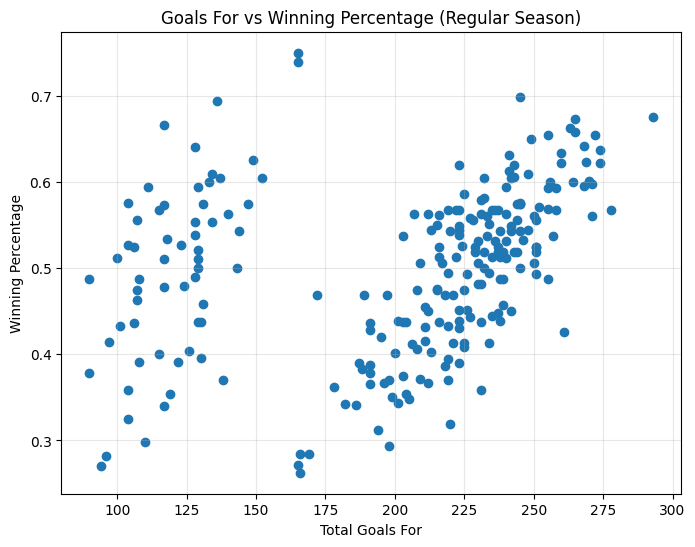

In [43]:
plt.figure(figsize=(8,6))
plt.scatter(NHL_Team_R_Stats["goals_for"], NHL_Team_R_Stats["win_pct"])
plt.xlabel("Total Goals For")
plt.ylabel("Winning Percentage")
plt.title("Goals For vs Winning Percentage (Regular Season)")
plt.grid(True, alpha=0.3)
plt.show()

b) Add a regression line to the scatter plot.

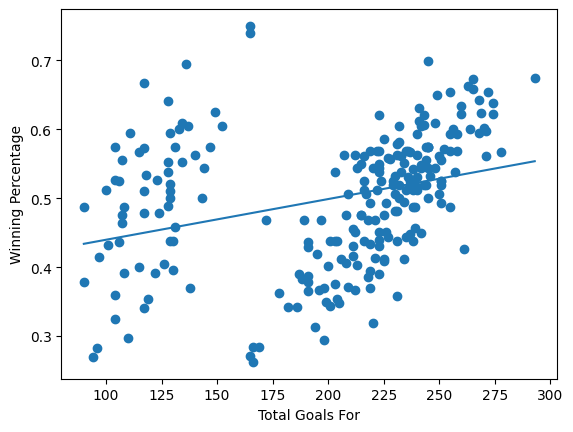

In [44]:
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values

m, b = np.polyfit(x, y, 1)              # slope, intercept
xline = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y)
plt.plot(xline, m*xline + b)
plt.xlabel("Total Goals For")
plt.ylabel("Winning Percentage")
plt.show()

c) Make the title of the graph “Relationship between Goals for and Winning Percentage” and make the font size 11.

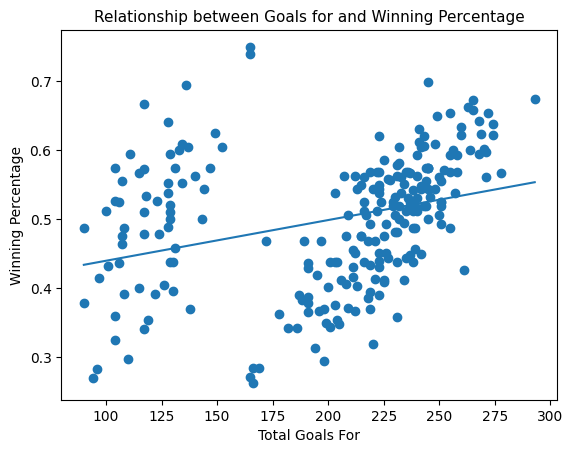

In [45]:
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values

m, b = np.polyfit(x, y, 1)              # slope, intercept
xline = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y)
plt.plot(xline, m*xline + b)
plt.xlabel("Total Goals For")
plt.ylabel("Winning Percentage")
plt.title("Relationship between Goals for and Winning Percentage", fontsize=11)
plt.show()

In the “NHL_Team_R_Stats” dataframe, calculate the correlation coefficient between total number of goals for and winning percentage.

In [46]:
corr = NHL_Team_R_Stats["goals_for"].corr(NHL_Team_R_Stats["win_pct"])
corr

np.float64(0.31566456280848165)

In the “NHL_Team_R_Stats” dataframe, make a scatter plot to depict the relationship between the total number of goals for and the winning percentage. 

a) Plot the total number of goals for on the x-axis and winning percentage on the y-axis.

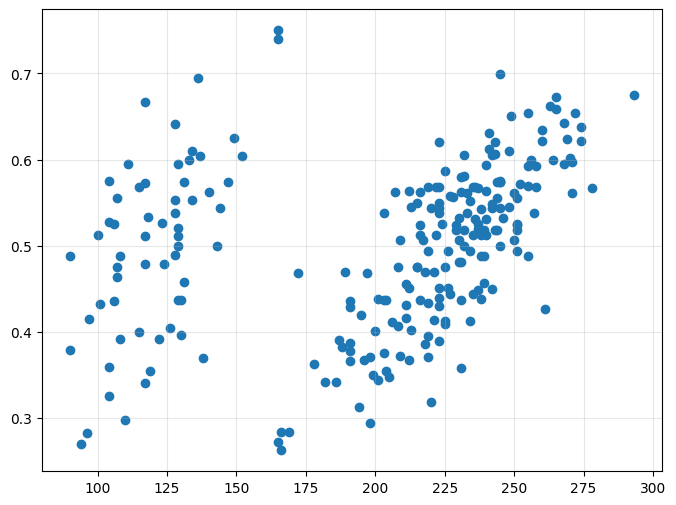

In [47]:
plt.figure(figsize=(8,6))
plt.scatter(NHL_Team_R_Stats["goals_for"], NHL_Team_R_Stats["win_pct"])
plt.grid(True, alpha=0.3)
plt.show()

b) Add a regression line to the scatter plot.

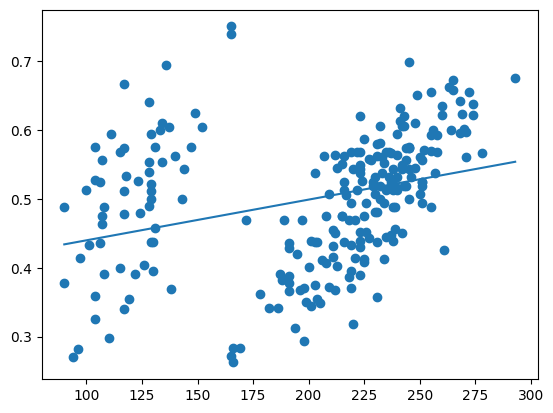

In [48]:
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values

m, b = np.polyfit(x, y, 1)              # slope, intercept
xline = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y)
plt.plot(xline, m*xline + b)
plt.show()

c) Make the title of the graph “Relationship between Goals for and Winning Percentage” and make the font size 11.

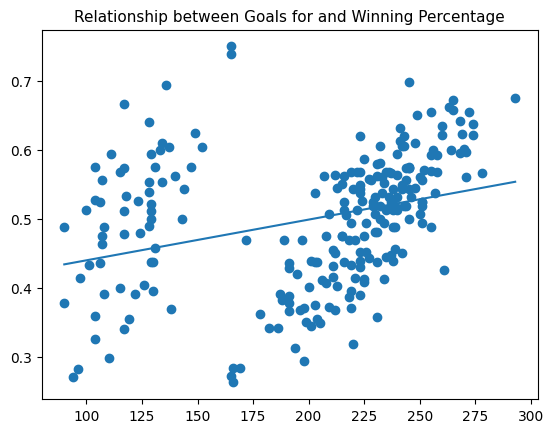

In [49]:
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values

m, b = np.polyfit(x, y, 1)              # slope, intercept
xline = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y)
plt.plot(xline, m*xline + b)
plt.title("Relationship between Goals for and Winning Percentage", fontsize=11)
plt.show()


d) Label the x-axis “Total Goals for” and label the y-axis “Winning Percentage”.

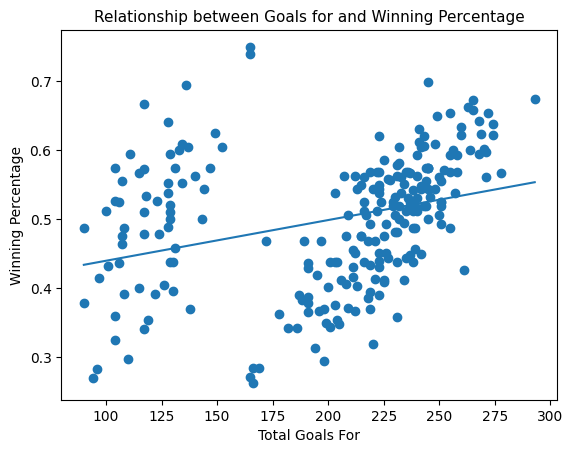

In [50]:
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values

m, b = np.polyfit(x, y, 1)              # slope, intercept
xline = np.linspace(x.min(), x.max(), 100)

plt.scatter(x, y)
plt.plot(xline, m*xline + b)
plt.xlabel("Total Goals For")
plt.ylabel("Winning Percentage")
plt.title("Relationship between Goals for and Winning Percentage", fontsize=11)
plt.show()

In the “NHL_Team_R_Stats” dataframe, calculate the correlation coefficient between total number of goals for and winning percentage.

corr = NHL_Team_R_Stats["goals_for"].corr(NHL_Team_R_Stats["win_pct"])
corr

Create a scatter plot of the total number of goals for and winning percentage similar to step 1 for regular season games. In this graph, group observations by “competition_name”.

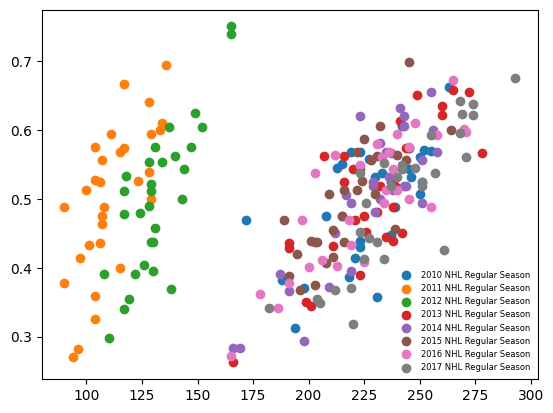

In [51]:
for comp, d in NHL_Team_R_Stats.groupby("competition_name"):
    plt.scatter(d["goals_for"], d["win_pct"], label=comp)

plt.legend(fontsize=6, frameon=False)
plt.show()

a) Plot the total number of goals for on the x-axis and winning percentage on the y-axis.

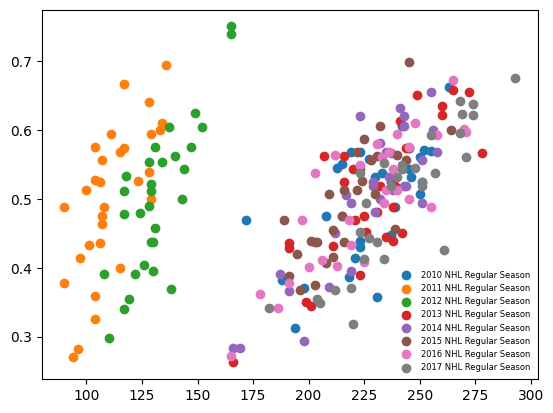

In [52]:
# scatter by competition_name (loop; matplotlib will auto-assign colors)
for comp, d in NHL_Team_R_Stats.groupby("competition_name"):
    plt.scatter(d["goals_for"].values, d["win_pct"].values, label=comp)


plt.legend(fontsize=6, frameon=False)

plt.show()

b) Add a regression line to the scatter plot.

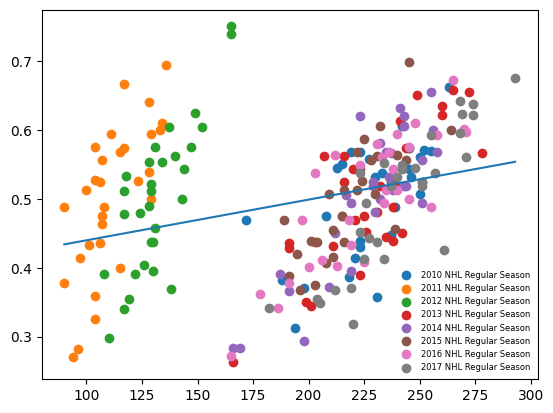

In [53]:
# scatter by competition_name (loop; matplotlib will auto-assign colors)
for comp, d in NHL_Team_R_Stats.groupby("competition_name"):
    plt.scatter(d["goals_for"].values, d["win_pct"].values, label=comp)

# regression line on all regular-season observations
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values
m, b = np.polyfit(x, y, 1)
xline = np.linspace(x.min(), x.max(), 100)
plt.plot(xline, m*xline + b)

plt.legend(fontsize=6, frameon=False)
plt.show()

c) Make the title of the graph “Relationship between Goals for and Winning Percentage” and make the font size 11.

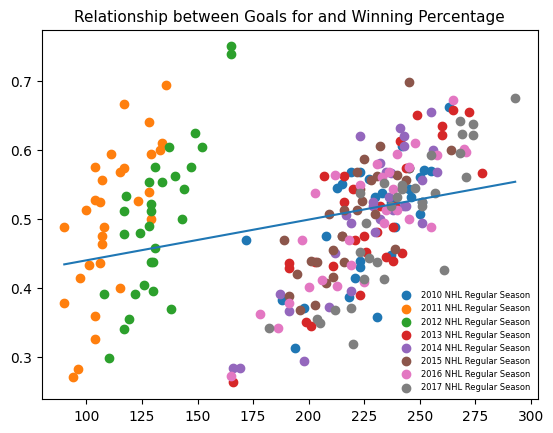

In [54]:
# scatter by competition_name (loop; matplotlib will auto-assign colors)
for comp, d in NHL_Team_R_Stats.groupby("competition_name"):
    plt.scatter(d["goals_for"].values, d["win_pct"].values, label=comp)

# regression line on all regular-season observations
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values
m, b = np.polyfit(x, y, 1)
xline = np.linspace(x.min(), x.max(), 100)
plt.plot(xline, m*xline + b)

plt.title("Relationship between Goals for and Winning Percentage", fontsize=11)
plt.legend(fontsize=6, frameon=False)
plt.show()

d) Label the x-axis “Total Goals for” and label the y-axis “Winning Percentage”.

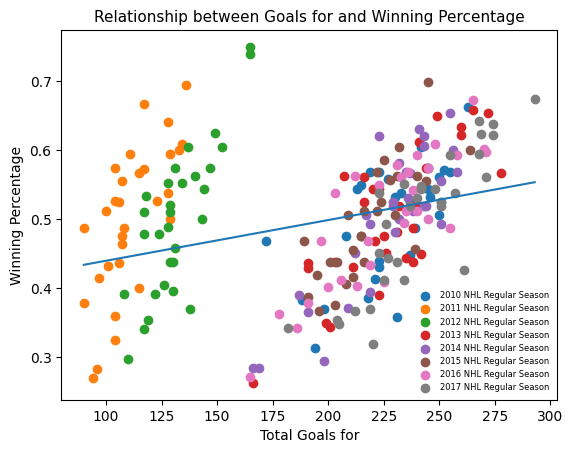

In [55]:
# scatter by competition_name (loop; matplotlib will auto-assign colors)
for comp, d in NHL_Team_R_Stats.groupby("competition_name"):
    plt.scatter(d["goals_for"].values, d["win_pct"].values, label=comp)

# regression line on all regular-season observations
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values
m, b = np.polyfit(x, y, 1)
xline = np.linspace(x.min(), x.max(), 100)
plt.plot(xline, m*xline + b)

plt.title("Relationship between Goals for and Winning Percentage", fontsize=11)
plt.xlabel("Total Goals for")
plt.ylabel("Winning Percentage")
plt.legend(fontsize=6, frameon=False)
plt.show()

For the “NHL_Team_R_Stats” dataframe, delete observations of 2011 and 2012 seasons. Continue to name the dataframe “NHL_Team_R_Stats”.

In [56]:
NHL_Team_R_Stats = NHL_Team_R_Stats.loc[~NHL_Team_R_Stats["competition_name"].str.contains("2011|2012")].copy()
NHL_Team_R_Stats

,tricode,pp,pk,ppgf,competition_name,tid,type,win,goals_for,goals_against,game_count,team_name,win_pct,avg_gf,avg_ga
16,ANA,401,378,92.0,2010 NHL Regular Season,21,2,43.5,227.0,225.0,78,Anaheim Ducks,0.557692,2.910256,2.884615
17,ATL,338,341,35.0,2010 NHL Regular Season,11366,2,34.0,223.0,263.0,79,Atlanta Thrashers,0.430380,2.822785,3.329114
18,BOS,368,370,74.0,2010 NHL Regular Season,20,2,46.0,250.0,200.0,82,Boston Bruins,0.560976,3.048780,2.439024
19,BUF,393,364,83.0,2010 NHL Regular Season,17,2,43.0,251.0,235.0,82,Buffalo Sabres,0.524390,3.060976,2.865854
20,CAR,338,427,79.0,2010 NHL Regular Season,66,2,40.0,239.0,242.0,82,Carolina Hurricanes,0.487805,2.914634,2.951220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364,TOR,256,245,58.0,2017 NHL Regular Season,1,2,47.0,268.0,232.0,79,Toronto Maple Leafs,0.594937,3.392405,2.936709
365,VAN,299,272,63.0,2017 NHL Regular Season,53,2,30.0,219.0,268.0,81,Vancouver Canucks,0.370370,2.703704,3.308642
366,VGK,257,273,64.0,2017 NHL Regular Season,59,2,50.5,269.0,223.0,81,Vegas Golden Knights,0.623457,3.320988,2.753086
367,WPG,307,304,69.0,2017 NHL Regular Season,4,2,51.0,274.0,214.0,80,Winnipeg Jets,0.637500,3.425000,2.675000


In the new “NHL_Team_R_Stats” dataframe, create a scatter plot of total number of goals for and winning percentage.

a) Plot the total number of goals for on the x-axis and winning percentage on the y-axis.

b) Add a regression line to the scatter plot.

c) Make the title of the graph “Relationship between Goals for and Winning Percentage” and make the font size 11.

d) Label the x-axis “Total Goals for” and label the y-axis “Winning Percentage”.

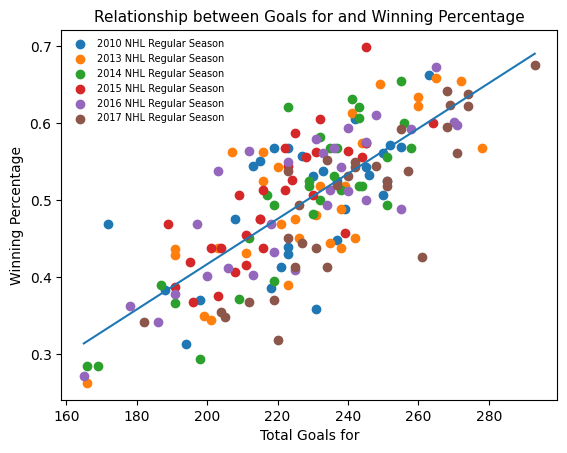

In [57]:
# scatter by competition_name (loop; matplotlib will auto-assign colors)
for comp, d in NHL_Team_R_Stats.groupby("competition_name"):
    plt.scatter(d["goals_for"].values, d["win_pct"].values, label=comp)

# regression line on all regular-season observations
x = NHL_Team_R_Stats["goals_for"].values
y = NHL_Team_R_Stats["win_pct"].values
m, b = np.polyfit(x, y, 1)
xline = np.linspace(x.min(), x.max(), 100)
plt.plot(xline, m*xline + b)

plt.title("Relationship between Goals for and Winning Percentage", fontsize=11)
plt.xlabel("Total Goals for")
plt.ylabel("Winning Percentage")
plt.legend(fontsize=7, frameon=False)
plt.show()

Calculate the correlation coefficient between total number of goals for and winning percentage in the updated “NHL_Team_R_Stats” dataframe.

In [58]:
corr = NHL_Team_R_Stats["goals_for"].corr(NHL_Team_R_Stats["win_pct"])
corr

np.float64(0.770625532180144)

Save dataframes as csv files. 

a) Name the updated “NHL_Game” dataframe as “NHL_Game2”.

b) Name the “NHL_Team_Stats” dataframe as “NHL_Team_Stats”.

c) Name the “NHL_Team_R_Stats” dataframe as “NHL_Team_R_Stats”.

d) Make sure to exclude the index as a column in the csv files.

In [59]:
NHL_Game2 = NHL_game.copy()

NHL_Game2.to_csv("NHL_Game2.csv", index=False)
NHL_Team_Stats.to_csv("NHL_Team_Stats.csv", index=False)
NHL_Team_R_Stats.to_csv("NHL_Team_R_Stats.csv", index=False)
